# Exp1 analysis 7: body KV patching (F1 recipient)

In [1]:
import json
import os
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

RUN = Path(os.environ['KV_RUN']) if 'KV_RUN' in os.environ else sorted(p for p in Path('../runs').iterdir() if (p / 'exp1_patch' / 'results.jsonl').exists())[-1]
FIG = Path(os.environ.get('KV_FIG', '../figures/exp1'))
FIG.mkdir(parents=True, exist_ok=True)
ROWS = [json.loads(l) for l in (RUN / 'exp1_patch' / 'results.jsonl').read_text().splitlines()]
DONORS = ('H+', 'H-', 'C+', 'C-', 'P1', 'P2', 'F2')
G = defaultdict(list)
for r in ROWS:
    G[r['donor'], r['config']].append((r['recovery'], r['cont_logprob_delta']))
NL = 1 + max(int(c.split('_')[1]) for _, c in G if c.startswith('layer_'))


def stat(d, c, k=0):
    a = np.array(G[d, c])[:, k]
    return a.mean(), a.std()


print(RUN.name, len(ROWS), 'rows', len({r['passage'] for r in ROWS}), 'passages')

bbc-v1 69925 rows 25 passages


H+ all_kv -0.15±0.58 lp +6.14  all_k -0.18±0.38 lp +3.06  all_v -0.28±0.77 lp +4.89
H- all_kv -1.30±2.37 lp +5.52  all_k +0.01±0.23 lp -1.29  all_v -0.18±1.37 lp +5.50
C+ all_kv +0.22±0.28 lp +6.99  all_k -0.05±0.26 lp +4.89  all_v +0.25±0.28 lp +5.32
C- all_kv -1.23±2.02 lp +10.96  all_k -0.02±0.32 lp +4.01  all_v -0.16±1.29 lp +9.29
P1 all_kv -0.11±0.09 lp -0.59  all_k +0.05±0.05 lp +2.07  all_v -0.08±0.06 lp -0.21
P2 all_kv +0.13±0.19 lp +6.00  all_k +0.03±0.08 lp +1.12  all_v +0.03±0.06 lp +3.30
F2 all_kv +0.87±0.22 lp +8.11  all_k -0.07±0.31 lp -0.42  all_v +0.60±0.27 lp +7.93
reverse_all_kv +0.22±0.10 lp +13.73
shuffled_all_kv -0.14±0.16 lp -1.62


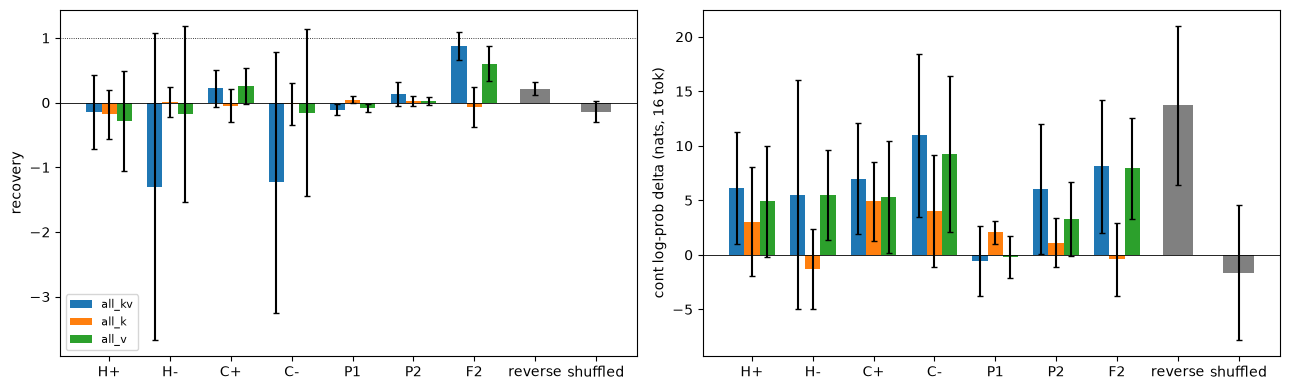

In [2]:
# Recovery = 1 - KL(D||patched)/KL(D||F1) at the token after the empty think block; F2 as donor is the filler-vs-filler floor.
CFG = ('all_kv', 'all_k', 'all_v')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, k, lab in zip(axes, (0, 1), ('recovery', 'cont log-prob delta (nats, 16 tok)')):
    w = 0.25
    for j, c in enumerate(CFG):
        m = [stat(d, c, k) for d in DONORS]
        ax.bar(np.arange(len(DONORS)) + (j - 1) * w, [x[0] for x in m], w, yerr=[x[1] for x in m], capsize=2, label=c)
    for x, (d, c, name) in enumerate([('F1', 'reverse_all_kv', 'reverse P1<-F1'), ('P1_shuffled', 'shuffled_all_kv', 'shuffled P1')]):
        mu, sd = stat(d, c, k)
        ax.bar(len(DONORS) + x, mu, w * 2, yerr=sd, capsize=2, color='gray')
    ax.set_xticks(range(len(DONORS) + 2), [*DONORS, 'reverse', 'shuffled'])
    ax.axhline(0, color='k', lw=0.6)
    ax.set_ylabel(lab)
axes[0].axhline(1, color='k', ls=':', lw=0.6)
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / 'patch_summary.png', dpi=120)
for d in DONORS:
    print(d, '  '.join(f'{c} {stat(d, c)[0]:+.2f}±{stat(d, c)[1]:.2f} lp {stat(d, c, 1)[0]:+.2f}' for c in CFG))
for d, c in [('F1', 'reverse_all_kv'), ('P1_shuffled', 'shuffled_all_kv')]:
    print(c, f'{stat(d, c)[0]:+.2f}±{stat(d, c)[1]:.2f} lp {stat(d, c, 1)[0]:+.2f}')

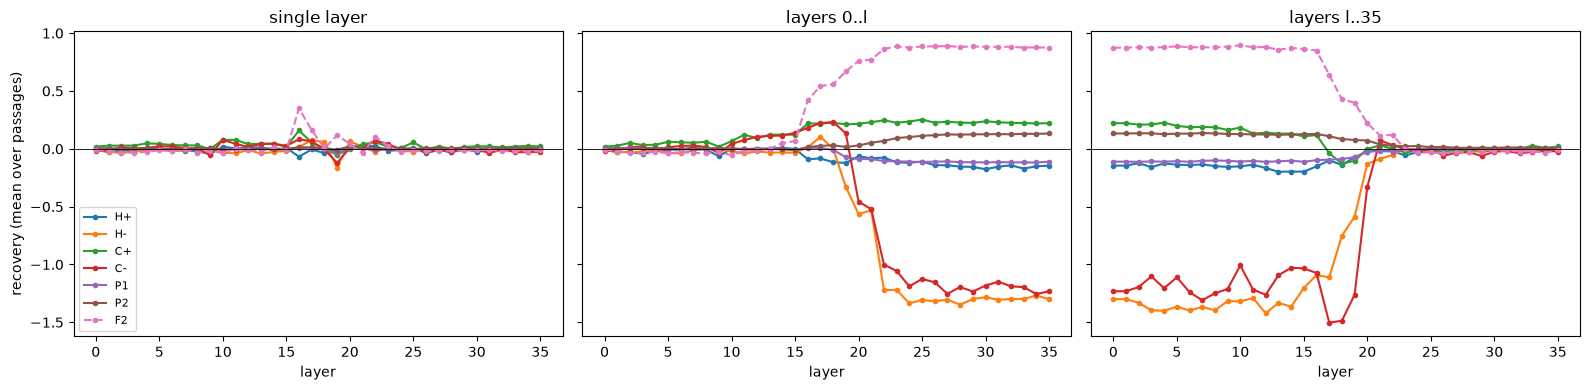

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, (pre, title) in zip(axes, [('layer_', 'single layer'), ('cum_fwd_', 'layers 0..l'), ('cum_bwd_', f'layers l..{NL - 1}')]):
    for d in DONORS:
        m = np.array([stat(d, f'{pre}{l}') for l in range(NL)])
        ax.plot(range(NL), m[:, 0], marker='.', label=d, ls='--' if d == 'F2' else '-')
    ax.axhline(0, color='k', lw=0.6)
    ax.set_title(title)
    ax.set_xlabel('layer')
axes[0].set_ylabel('recovery (mean over passages)')
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / 'patch_layers.png', dpi=120)

heads from bbc-v1 25 passages
H+ max head (np.int64(10), np.int64(2)) +0.04 min (np.int64(19), np.int64(3)) -0.12
H- max head (np.int64(20), np.int64(0)) +0.05 min (np.int64(22), np.int64(1)) -0.04
C+ max head (np.int64(16), np.int64(3)) +0.08 min (np.int64(19), np.int64(3)) -0.08
C- max head (np.int64(10), np.int64(2)) +0.08 min (np.int64(16), np.int64(2)) -0.09
P1 max head (np.int64(16), np.int64(2)) +0.02 min (np.int64(19), np.int64(4)) -0.02
P2 max head (np.int64(19), np.int64(3)) +0.02 min (np.int64(19), np.int64(2)) -0.01
F2 max head (np.int64(16), np.int64(3)) +0.19 min (np.int64(16), np.int64(4)) -0.07


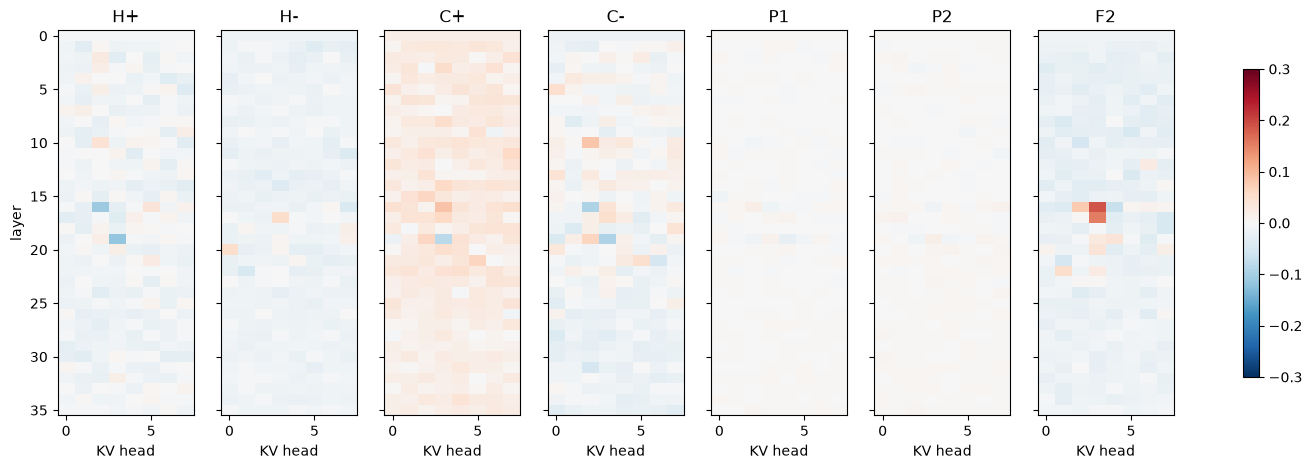

In [4]:
# Head sweeps are skipped in the 30-passage runs (--no-heads), so heads come from the latest run that has them.
HRUN = RUN if 'KV_RUN' in os.environ else sorted(p for p in Path('../runs').iterdir() if (p / 'exp1_patch' / 'results.jsonl').exists()
              and '"head_0_0"' in (p / 'exp1_patch' / 'results.jsonl').read_text())[-1]
HROWS = [json.loads(l) for l in (HRUN / 'exp1_patch' / 'results.jsonl').read_text().splitlines()]
HG = defaultdict(list)
for r in HROWS:
    HG[r['donor'], r['config']].append((r['recovery'], r['cont_logprob_delta']))
print('heads from', HRUN.name, len({r['passage'] for r in HROWS}), 'passages')
NH = 1 + max(int(c.split('_')[2]) for _, c in HG if c.startswith('head_'))
fig, axes = plt.subplots(1, len(DONORS), figsize=(18, 5), sharey=True)
for ax, d in zip(axes, DONORS):
    H = np.array([[np.mean(np.array(HG[d, f'head_{l}_{h}'])[:, 0]) for h in range(NH)] for l in range(NL)])
    im = ax.imshow(H, aspect='auto', cmap='RdBu_r', vmin=-0.3, vmax=0.3)
    ax.set_title(d)
    ax.set_xlabel('KV head')
    i = np.unravel_index(H.argmax(), H.shape)
    print(d, 'max head', i, f'{H.max():+.2f}', 'min', np.unravel_index(H.argmin(), H.shape), f'{H.min():+.2f}')
axes[0].set_ylabel('layer')
fig.colorbar(im, ax=axes, shrink=0.8)
fig.savefig(FIG / 'patch_heads.png', dpi=120, bbox_inches='tight')